# CSC173 · Deep Learning for Computer Vision
## Assignment notebook: convolution, pooling and pretrained CNNs on your own photos

In this notebook every experiment runs on **photos you take yourself**. It follows the lecture, in order:

1. Images are numbers: your photo as an array, in grayscale, and flattened
2. Convolution by hand: the output-size formula, your own `conv2d`, edge and blur filters, and a filter over all three color channels
3. Non-linearity and pooling: ReLU, max / average / sum pooling, and what pooling does when the image shifts
4. A pretrained CNN (MobileNetV2) classifies your photos, and how easily it is fooled
5. Inside the network: learned filters, feature maps at different depths, and where the network looks (Grad-CAM)
6. Beyond CNNs: your photo cut into Vision Transformer patches
7. Train a classifier on two categories of your own photos (transfer learning)

**How to work:** fill in every cell marked `# TODO`, run the cells from top to bottom, and answer each ✍️ question in the cell below it. Many answers depend on your photos, so describe what *you* see. Submit the notebook **with its outputs**.

**How to run:** Google Colab is easiest (TensorFlow is already installed, and the upload buttons work). In VS Code / Jupyter, run `pip install tensorflow pillow matplotlib` and put your photos in the folders described in Part 0.

### What photos you need

| For | What | How many |
|---|---|---|
| Parts 1 to 6 | Photos you took yourself. Include **one with strong straight edges** (a building, a window, a page of text, a staircase) and **one of an everyday object** (a mug, a keyboard, a shoe, a bicycle, a pet). | 3 to 5 |
| Part 7 | Two categories of objects you can photograph many times, such as *mango vs. banana*, *my pen vs. my pencil*, *jeepney vs. tricycle*. Vary the background, angle and lighting. | at least 20 per category |

Use JPG or PNG. Do not use photos of other people without their permission.

In [1]:
import os, glob, shutil, zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps, ImageEnhance, ImageFilter

tf.keras.utils.set_random_seed(173)   # same random numbers every run, so results are repeatable
np.set_printoptions(precision=3, suppress=True)
print("TensorFlow", tf.__version__)

try:
    from google.colab import files     # only exists on Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running on Colab:", IN_COLAB)

TensorFlow 2.21.0
Running on Colab: True


---
## 0. Bring your own photos

Run the cell below and pick 3 to 5 of your photos. Outside Colab, copy them into a folder named `my_images` next to this notebook first. Running the cell again on Colab lets you add more photos.

In [2]:
IMG_DIR = "my_images"
os.makedirs(IMG_DIR, exist_ok=True)
if IN_COLAB:
    uploaded = files.upload()                       # choose 3 to 5 photos
    for name, data in uploaded.items():
        with open(os.path.join(IMG_DIR, name), "wb") as f:
            f.write(data)

paths = sorted(p for p in glob.glob(os.path.join(IMG_DIR, "*"))
               if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")))
if not paths:
    print("No photos found in my_images/, so a sample photo is used for now. Your submission must use YOUR photos.")
    paths = [tf.keras.utils.get_file("grace_hopper.jpg",
             "https://storage.googleapis.com/download.tensorflow.org/example_images/grace_hopper.jpg")]
print(len(paths), "photo(s):", [os.path.basename(p) for p in paths])

Saving remote.jpg to remote.jpg
Saving spoon.jpg to spoon.jpg
Saving mug.jpg to mug.jpg
Saving keyboard.jpg to keyboard.jpg
Saving window.jpg to window.jpg
5 photo(s): ['keyboard.jpg', 'mug.jpg', 'remote.jpg', 'spoon.jpg', 'window.jpg']


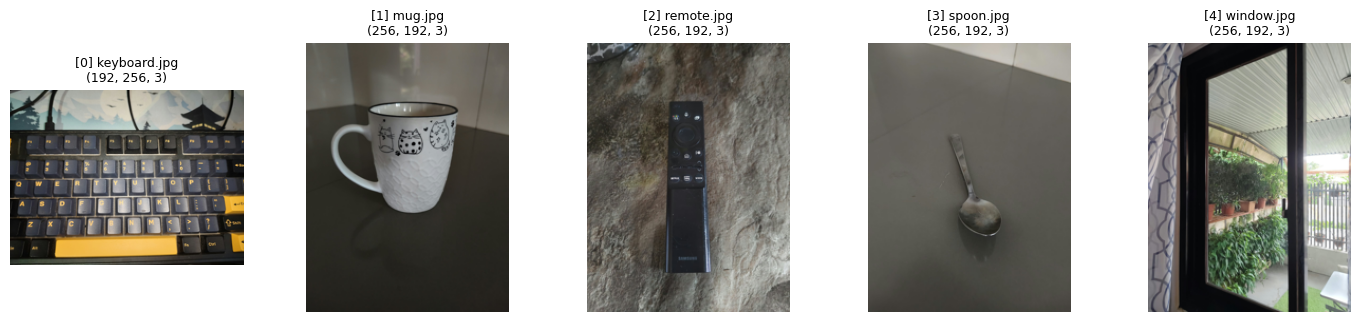

In [3]:
def open_photo(path):
    """Open a photo as an RGB PIL image, turned the right way up (phones store rotation separately)."""
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

def load_image(path, max_side=256):
    """Open a photo and shrink it so its longest side is max_side pixels. Returns a uint8 array (H, W, 3)."""
    img = open_photo(path)
    img.thumbnail((max_side, max_side))
    return np.array(img)

images = [load_image(p) for p in paths]
fig, axes = plt.subplots(1, len(images), figsize=(3.5 * len(images), 3.5), squeeze=False)
for k, (ax, im) in enumerate(zip(axes[0], images)):
    ax.imshow(im); ax.set_title(f"[{k}] {os.path.basename(paths[k])}\n{im.shape}", fontsize=9); ax.axis("off")
plt.show()

Pick the photo with the **strongest straight edges** for Parts 1 to 3 by setting `MY_PICK` to its number in the titles above.

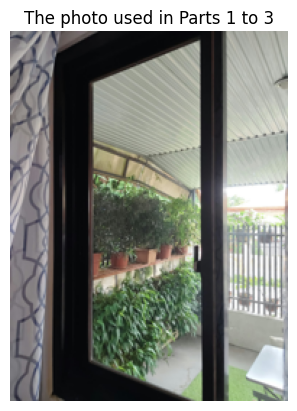

In [4]:
MY_PICK = 4          # change this to the number of your photo with strong edges
img = images[MY_PICK]
plt.imshow(img); plt.axis("off"); plt.title("The photo used in Parts 1 to 3"); plt.show()

---
## 1. Images are numbers

From the slides *Images are Numbers*: a color image is a grid of pixels, and every pixel holds three numbers (red, green, blue), each from 0 to 255.

### 1a. Your photo as an array

shape : (256, 192, 3)   (height, width, channels)
dtype : uint8
min / max: 2 / 255
numbers in this photo: 147456
Check: True

Red channel, top-left 6×6 pixels:
[[111 128 132 138 139 137]
 [107 129 137 141 135 128]
 [106 139 140 128 111 106]
 [120 115  86  64  46  50]
 [ 75  73  76  78  67  58]
 [111 123 120 116 112 108]]


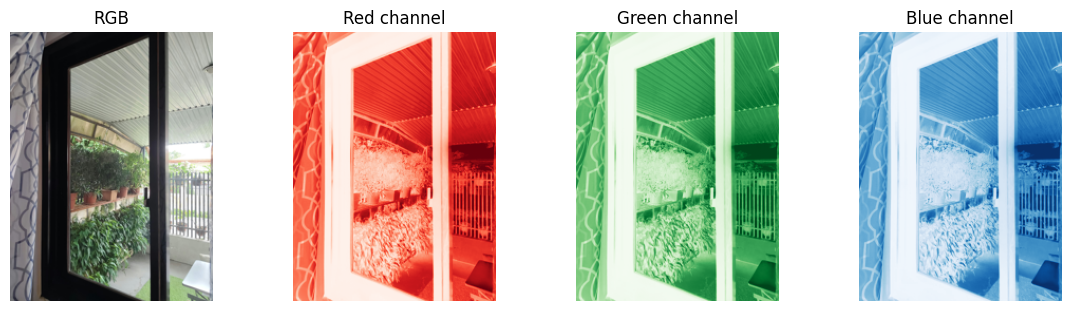

In [5]:
print("shape :", img.shape, "  (height, width, channels)")
print("dtype :", img.dtype)
print("min / max:", img.min(), "/", img.max())

n_values = img.size   # TODO: how many numbers in total describe this photo?
print("numbers in this photo:", n_values)
print("Check:", n_values == img.shape[0] * img.shape[1] * img.shape[2])

print("\nRed channel, top-left 6×6 pixels:")
print(img[:6, :6, 0])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(img); axes[0].set_title("RGB")
for c, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    axes[c + 1].imshow(img[:, :, c], cmap=cmap, vmin=0, vmax=255); axes[c + 1].set_title(f"{name} channel")
for ax in axes: ax.axis("off")
plt.show()

### 1b. Grayscale

Most of Parts 2 and 3 use a single channel. The usual grayscale formula weights the channels by how sensitive our eyes are to them:

$$\text{gray} = 0.299\,R + 0.587\,G + 0.114\,B$$

Compute it and scale it to the range $[0, 1]$.

gray shape: (256, 192)  range: 0.011 to 1.0
Matches tf.image.rgb_to_grayscale: True


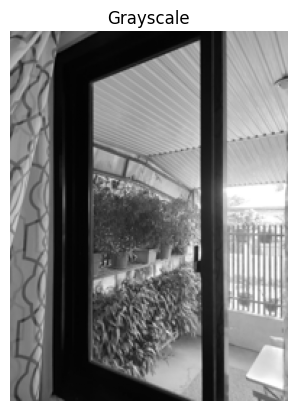

In [6]:
R, G, B = [img[:, :, c].astype("float32") for c in range(3)]
gray = (0.299 * R + 0.587 * G + 0.114 * B) / 255.0

tf_gray = tf.image.rgb_to_grayscale(img).numpy()[:, :, 0] / 255.0
print("gray shape:", gray.shape, " range:", gray.min().round(3), "to", gray.max().round(3))
print("Matches tf.image.rgb_to_grayscale:", np.allclose(gray, tf_gray, atol=0.01))
plt.imshow(gray, cmap="gray"); plt.axis("off"); plt.title("Grayscale"); plt.show()

### 1c. Flattening

A fully connected (Dense) network needs one long vector, so the slide *Flatten* unrolls the image. How many weights would one Dense layer of 1,000 neurons need on top of it?

In [7]:
x_flat = img.flatten()   # TODO: unroll the whole (H, W, 3) array into one vector
print("flattened length:", x_flat.size)

def dense_params(n_inputs, n_neurons):
    return (n_inputs * n_neurons) + n_neurons   # TODO: weights plus biases
print(f"Dense(1000) on your photo   : {dense_params(x_flat.size, 1000):,} parameters")
print(f"Dense(1000) on 224×224×3    : {dense_params(224 * 224 * 3, 1000):,} parameters")
print("Check:", dense_params(4, 3) == 15)

flattened length: 147456
Dense(1000) on your photo   : 147,457,000 parameters
Dense(1000) on 224×224×3    : 150,529,000 parameters
Check: True


✍️ **Question 1.**
1. Look at the 6×6 block of red values. Do the numbers agree with what you see in that corner of your photo (bright or dark, smooth or busy)?
2. Write the number of parameters of a Dense(1000) layer on a 224×224×3 image. Why is that a problem?
3. If the object in your photo moved 10 pixels to the right, what would happen to `x_flat`? Why does that make life hard for a Dense network?

*Your answer:*

1. The 6×6 red block holds medium values that change a lot from one pixel to the next (for example 120, 115, 86, 64, 46, 50 in one row). This agrees with the top-left corner of my window photo, which is the patterned curtain: medium brightness with dark pattern lines, so it is busy, not smooth.

2. 224 × 224 × 3 = 150,528 inputs, so Dense(1000) has 150,528 × 1000 + 1000 = 150,529,000 parameters. This is a problem because it needs a huge memory and huge amount of data, this overfits easily, and the count grows with every pixel.

3. The object's pixel values would move to other positions in x_flat, so a lot of entries would change. A Dense layer has a separate weight for every position, so it has to relearn the same object at every location.

---
## 2. Convolution by hand

### 2a. Output size

From the slides on stride and padding: an $n \times n$ input, a $k \times k$ kernel, padding $p$ and stride $s$ give an output of size

$$\left\lfloor \frac{n - k + 2p}{s} \right\rfloor + 1$$

In [8]:
def conv_output_size(n, k, p=0, s=1):
    return ((n - k + (2 * p)) // s) + 1   # TODO: the formula above (use // for the floor)

print(conv_output_size(5, 3), conv_output_size(5, 3, p=1), conv_output_size(7, 3, s=2), conv_output_size(224, 11, p=2, s=4))
print("Check:", (conv_output_size(5, 3), conv_output_size(5, 3, p=1), conv_output_size(7, 3, s=2), conv_output_size(224, 11, p=2, s=4)) == (3, 5, 3, 55))

3 5 3 55
Check: True


### 2b. Your own `conv2d`

Slide the kernel over the image. At each position, multiply the kernel with the patch under it element by element and add everything up. (CNNs do not flip the kernel, so this is what `tf.nn.conv2d` computes.)

In [9]:
def conv2d(x, kernel, stride=1, padding=0):
    """Convolve a 2-D array x (H, W) with a square kernel (k, k). Returns the 2-D feature map."""
    if padding > 0:
        x = np.pad(x, padding)   # TODO: add `padding` rows and columns of zeros on every side (np.pad)
    k = kernel.shape[0]
    H_out = conv_output_size(x.shape[0], k, 0, stride)
    W_out = conv_output_size(x.shape[1], k, 0, stride)
    out = np.zeros((H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            window = x[i * stride : i * stride + k, j * stride : j * stride + k]   # TODO: the k×k patch under the kernel
            out[i, j] = np.sum(window * kernel)   # TODO: multiply element by element and add up
    return out

# A tiny test you can check by hand: every output is x[i, j] - x[i+1, j+1] = -5
x_test = np.arange(16).reshape(4, 4)
print(conv2d(x_test, np.array([[1, 0], [0, -1]])))

def tf_conv(x, kernel, stride=1, padding=0):
    """The same operation with TensorFlow, to check our version."""
    x = np.pad(x, padding)[None, :, :, None].astype("float32")          # (batch, H, W, channels)
    w = kernel[:, :, None, None].astype("float32")                      # (k, k, in_channels, out_channels)
    return tf.nn.conv2d(x, w, strides=stride, padding="VALID").numpy()[0, :, :, 0]

k_test = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype="float32")
for s, p in [(1, 0), (1, 1), (2, 1)]:
    mine = conv2d(gray, k_test, stride=s, padding=p)
    print(f"stride {s}, padding {p}: output {mine.shape}, matches tf.nn.conv2d: {np.allclose(mine, tf_conv(gray, k_test, s, p), atol=1e-4)}")

[[-5. -5. -5.]
 [-5. -5. -5.]
 [-5. -5. -5.]]
stride 1, padding 0: output (254, 190), matches tf.nn.conv2d: True
stride 1, padding 1: output (256, 192), matches tf.nn.conv2d: True
stride 2, padding 1: output (128, 96), matches tf.nn.conv2d: True


### 2c. Filters on your photo

The first four kernels are the classic ones from the slide *Convolution Examples*. The last one is yours: design a kernel that detects something the others do not, such as diagonal edges, or an emboss effect. It can be 3×3 or 5×5.

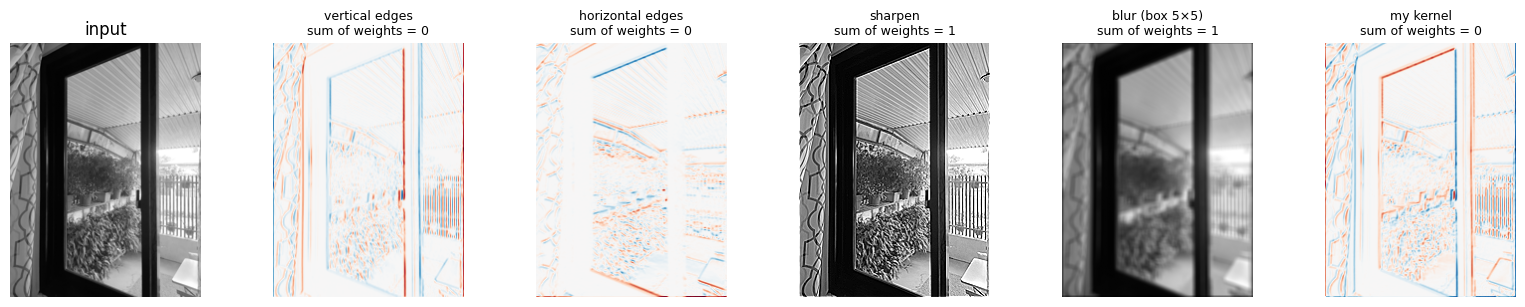

In [10]:
kernels = {
    "vertical edges":   np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]]),
    "horizontal edges": np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]]),
    "sharpen":          np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "blur (box 5×5)":   np.ones((5, 5)) / 25,
    "my kernel":        np.array([[-2, -1, 0], [-1, 0, 1], [0, 1, 2]]),   # TODO: replace this "do nothing" kernel with your own design
}

fig, axes = plt.subplots(1, len(kernels) + 1, figsize=(3.3 * (len(kernels) + 1), 3.3))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("input")
for ax, (name, kern) in zip(axes[1:], kernels.items()):
    fmap = conv2d(gray, kern.astype("float32"), padding=kern.shape[0] // 2)
    if kern.sum() == 0:                       # edge detectors: negative and positive responses
        v = np.abs(fmap).max()
        ax.imshow(fmap, cmap="RdBu_r", vmin=-v, vmax=v)
    else:
        ax.imshow(np.clip(fmap, 0, 1), cmap="gray")
    ax.set_title(f"{name}\nsum of weights = {kern.sum():.2g}", fontsize=9)
for ax in axes: ax.axis("off")
plt.show()

✍️ **Question 2.**
1. Which parts of your photo respond strongly to the vertical-edge kernel, and which to the horizontal-edge kernel? Why? (Red and blue are opposite signs: what does the sign tell you?)
2. What does *your* kernel detect? Explain from its numbers.
3. Edge kernels have weights that sum to 0 and the blur kernel's weights sum to 1. What does each do to a flat region of the photo, such as a clear wall or sky?
4. Your grayscale photo has some size $H \times W$. Use `conv_output_size` to give the output size of a 3×3 kernel with (stride 1, padding 0), (stride 1, padding 1) and (stride 2, padding 1). Which setting keeps the size?

*Your answer:*

1. The vertical-edge kernel responds strongly to the vertical bars of the window frame, the curtain pattern and the fence slats, because it compares the left and right neighbours of each pixel. The horizontal-edge kernel responds to the roof lines, the top and bottom edges of the window frame and the shelf, because it compares the top and bottom neighbours. The sign tells the direction of the change: red means the left side (or top side) is brighter, blue means the opposite.

2. My kernel is [[-2, -1, 0], [-1, 0, 1], [0, 1, 2]]. Its weights sum to 0, the upper-left weights are negative, the lower-right weights are positive, and the diagonal is all zeros.

3. Edge kernels which gives sum 0, because every pixel is the same and the positive and negative weights cancel, so only changes give a response. The blur kernel which has sum 1, a flat region keeps the same brightness, because the average of equal values is that value, and only detail is smoothed away.

4. My grayscale photo is H × W = 256 × 192. With a 3×3 kernel, (stride 1, padding 0) gives 254 × 190, (stride 1, padding 1) gives 256 × 192, and (stride 2, padding 1) gives 128 × 96. Stride 1 with padding 1 keeps the size.

### 2d. One filter over three color channels

From the slides on convolution over color images: a filter for an RGB image is $k \times k \times 3$. It convolves each channel with its own slice and **adds** the three results, so one filter still gives one 2-D feature map.

The filter below looks for **red things**: +1 on the red channel and −0.5 on green and blue, averaged over 5×5. Try it on a photo with something red (or change the weights to look for another color).

filter shape: (5, 5, 3) → weights in this filter: 75 (+1 bias in a CNN)
feature map shape: (256, 192)   matches tf.nn.conv2d: True


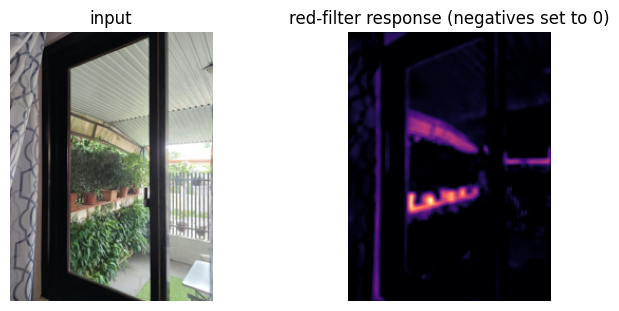

In [11]:
def conv2d_rgb(x, kernel3, stride=1, padding=0):
    """x: (H, W, 3), kernel3: (k, k, 3). Returns ONE 2-D feature map."""
    # Convolve each channel with its corresponding slice, then sum them up
    return sum(conv2d(x[:, :, c], kernel3[:, :, c], stride=stride, padding=padding) for c in range(3))

red_filter = np.stack([np.full((5, 5), 1.0), np.full((5, 5), -0.5), np.full((5, 5), -0.5)], axis=-1) / 25
x_rgb = img.astype("float32") / 255.0
red_map = conv2d_rgb(x_rgb, red_filter, padding=2)

tf_map = tf.nn.conv2d(np.pad(x_rgb, ((2, 2), (2, 2), (0, 0)))[None], red_filter[:, :, :, None].astype("float32"),
                      strides=1, padding="VALID").numpy()[0, :, :, 0]
print("filter shape:", red_filter.shape, "→ weights in this filter:", red_filter.size, "(+1 bias in a CNN)")
print("feature map shape:", red_map.shape, "  matches tf.nn.conv2d:", np.allclose(red_map, tf_map, atol=1e-4))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(img); axes[0].set_title("input")
axes[1].imshow(np.maximum(red_map, 0), cmap="magma"); axes[1].set_title("red-filter response (negatives set to 0)")
for ax in axes: ax.axis("off")
plt.show()

✍️ **Question 3.**
1. Where does the red filter respond in your photo? Is anything surprising (white or skin-colored areas, for example)?
2. This filter has 75 weights (plus 1 bias). How many would it have on a photo 10 times larger? Compare with your answer to Question 1.2.
3. A layer with 64 such filters on an RGB image: how many parameters, and what is the shape of its output for your photo (padding 2, stride 1)?

*Your answer:*

1. The red filter responds most on the terracotta (orange-red) flower pots on the shelf, with a weaker band along the orange-tinted roof edge. The white and gray areas do not respond at all, even though they contain a lot of red. The filter weights (1, -0.5, -0.5) add up to 0 across the channels, so white cancels itself.

2. It would still have 75 weights (+1 bias), because the number of weights depends on the kernel size and the number of channels, not on the image size. The Dense layer from Question 1.2 grows with the number of pixels: with 10 times more pixels in each direction (100 times more pixels) it would have about 14.7 billion parameters.

3. 64 × (5 × 5 × 3 + 1) = 64 × 76 = 4,864 parameters. With padding 2 and stride 1 the size is kept, so the output shape is (256, 192, 64).

---
## 3. Non-linearity and pooling

### 3a. ReLU and pooling by hand

$\text{ReLU}(x) = \max(0, x)$. Pooling slides a window (here 2×2 with stride 2) over each feature map and keeps one number per window: the **max**, the **average** or the **sum**.

In [12]:
def relu(x):
    return np.maximum(0, x)   # TODO

def pool2d(x, size=2, stride=2, mode="max"):
    """Pool a 2-D feature map. mode is "max", "avg" or "sum"."""
    H_out = conv_output_size(x.shape[0], size, 0, stride)
    W_out = conv_output_size(x.shape[1], size, 0, stride)
    out = np.zeros((H_out, W_out))
    for i in range(H_out):
        for j in range(W_out):
            window = x[i * stride : i * stride + size, j * stride : j * stride + size]
            if mode == "max":
                out[i, j] = np.max(window)   # TODO
            elif mode == "avg":
                out[i, j] = np.mean(window)   # TODO
            else:
                out[i, j] = np.sum(window)   # TODO
    return out

print(relu(np.array([-2.0, -0.5, 0.0, 1.5])), "  Check:", np.allclose(relu(np.array([-2.0, -0.5, 0.0, 1.5])), [0, 0, 0, 1.5]))
t = np.array([[1, 3, 2, 1], [4, 2, 0, 1], [5, 6, 1, 2], [7, 8, 3, 4]], dtype=float)
print("max:\n", pool2d(t), "\navg:\n", pool2d(t, mode="avg"), "\nsum:\n", pool2d(t, mode="sum"))

fm = conv2d(gray, kernels["vertical edges"].astype("float32"), padding=1)
tf_max = tf.nn.max_pool2d(fm[None, :, :, None], 2, 2, "VALID").numpy()[0, :, :, 0]
tf_avg = tf.nn.avg_pool2d(fm[None, :, :, None], 2, 2, "VALID").numpy()[0, :, :, 0]
print("Matches tf.nn.max_pool2d:", np.allclose(pool2d(fm), tf_max, atol=1e-5),
      "  tf.nn.avg_pool2d:", np.allclose(pool2d(fm, mode="avg"), tf_avg, atol=1e-5))

[0.  0.  0.  1.5]   Check: True
max:
 [[4. 2.]
 [8. 4.]] 
avg:
 [[2.5 1. ]
 [6.5 2.5]] 
sum:
 [[10.  4.]
 [26. 10.]]
Matches tf.nn.max_pool2d: True   tf.nn.avg_pool2d: True


### 3b. One CNN stage on your photo: convolution → ReLU → pooling

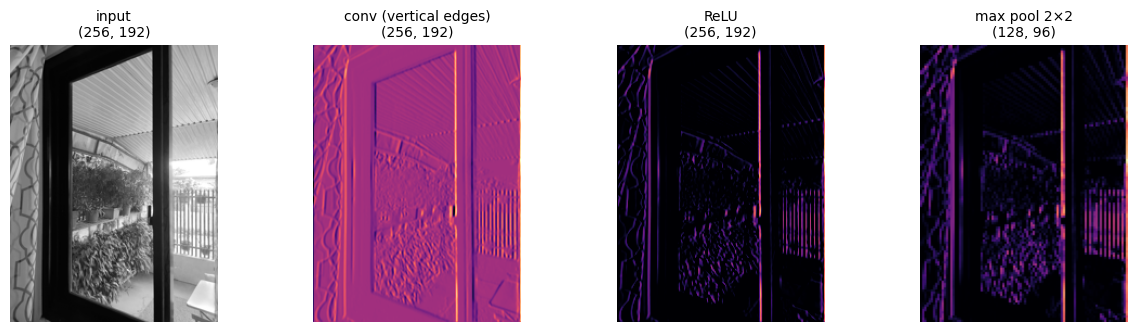

ReLU set 56% of the values to zero


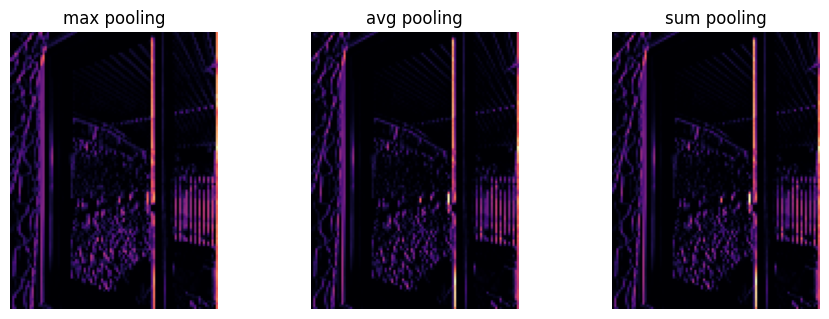

In [13]:
stage = {"input": gray}
stage["conv (vertical edges)"] = conv2d(gray, kernels["vertical edges"].astype("float32"), padding=1)
stage["ReLU"] = relu(stage["conv (vertical edges)"])
stage["max pool 2×2"] = pool2d(stage["ReLU"], size=2, stride=2, mode="max")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, a) in zip(axes, stage.items()):
    ax.imshow(a, cmap="gray" if name == "input" else "magma"); ax.set_title(f"{name}\n{a.shape}", fontsize=10); ax.axis("off")
plt.show()

zeros = np.mean(stage["ReLU"] == 0)
print(f"ReLU set {zeros:.0%} of the values to zero")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, mode in zip(axes, ["max", "avg", "sum"]):
    ax.imshow(pool2d(stage["ReLU"], mode=mode), cmap="magma"); ax.set_title(f"{mode} pooling"); ax.axis("off")
plt.show()

### 3c. Does pooling help when the photo shifts?

Shift your photo one pixel to the right and compare the feature maps before and after the shift, with and without pooling. We measure the change as $\lVert a - b \rVert / \lVert a \rVert$ (0 means identical).

In [14]:
def relative_change(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(a)   # TODO: the formula above (np.linalg.norm)

def stage_out(g, pool=None):
    a = relu(conv2d(g, kernels["vertical edges"].astype("float32"), padding=1))
    return a if pool is None else pool2d(a, size=pool, stride=pool, mode="max")

shifted = np.roll(gray, 1, axis=1)          # move every pixel one column to the right
for pool in [None, 2, 4]:
    a, b = stage_out(gray, pool), stage_out(shifted, pool)
    label = "no pooling" if pool is None else f"max pool {pool}×{pool}"
    print(f"{label:14s}: relative change after a 1-pixel shift = {relative_change(a, b):.3f}")

no pooling    : relative change after a 1-pixel shift = 0.859
max pool 2×2  : relative change after a 1-pixel shift = 0.594
max pool 4×4  : relative change after a 1-pixel shift = 0.361


✍️ **Question 4.**
1. What fraction of values did ReLU set to zero, and why is it so high for an edge map?
2. Compare max, average and sum pooling on your photo: which keeps thin edges best, and why?
3. In 3c, how did the change after a one-pixel shift depend on pooling? Explain how pooling makes the network less sensitive to small shifts, and what it loses in exchange.

*Your answer:*

1. ReLU set 56% of the values to zero. Most photo is smooth, and a smooth region gives about 0 for an edge kernel; the negative half of the edge responses is also cut to 0.

2. Max pooling keeps thin edges best, because it keeps the strongest response in each 2×2 window. Average pooling mixes a thin bright line with the dark pixels around it, so the line fades. Sum pooling has the same pattern as average pooling but with 4 times larger numbers.

3. After a one-pixel shift the relative change was 0.859 with no pooling, 0.594 with 2×2 max pooling and 0.361 with 4×4 max pooling, so more pooling means less change. After a 1-pixel shift a strong edge usually stays inside the same pooling window, so the maximum of that window barely changes. The exact position of an edge and fine detail are lost.

---
## 4. A pretrained CNN looks at your photos

**MobileNetV2** is a small, modern CNN trained on ImageNet (1.2 million photos, 1,000 classes). It expects 224×224 RGB images with pixels scaled to $[-1, 1]$.

MobileNetV2: 3,538,984 parameters, 156 layers
batch: (5, 224, 224, 3)  pixel range: -1.0 to 1.0


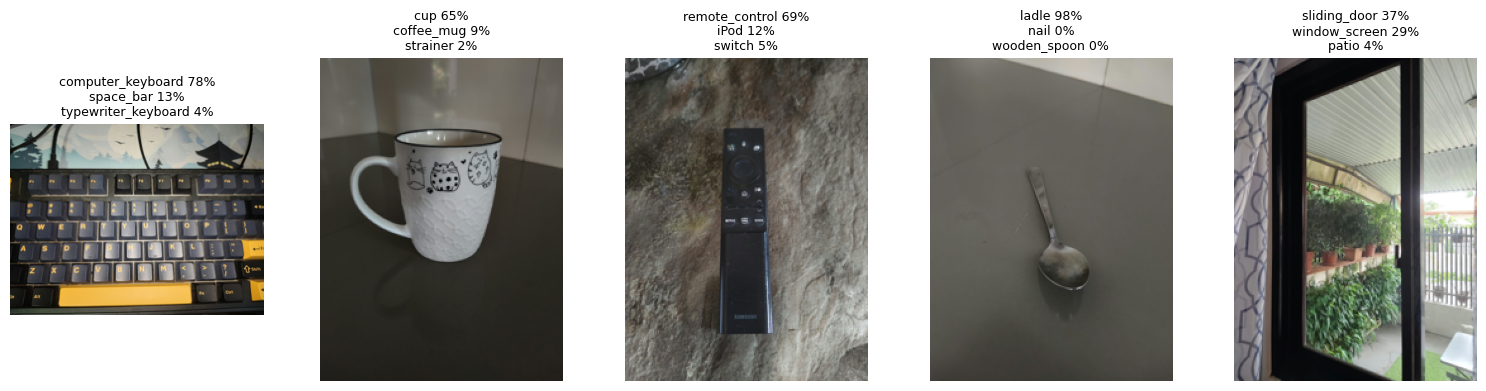

In [15]:
model = tf.keras.applications.MobileNetV2(weights="imagenet")    # downloads about 14 MB the first time
print(f"MobileNetV2: {model.count_params():,} parameters, {len(model.layers)} layers")

def prepare(pil_img):
    """PIL image → float array of shape (224, 224, 3), ready for MobileNetV2."""
    resized = pil_img.resize((224, 224))
    x = np.array(resized, dtype="float32")
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    return x

batch = np.stack([prepare(open_photo(p)) for p in paths])
print("batch:", batch.shape, " pixel range:", batch.min(), "to", batch.max())
preds = model.predict(batch, verbose=0)
top3 = tf.keras.applications.mobilenet_v2.decode_predictions(preds, top=3)

fig, axes = plt.subplots(1, len(paths), figsize=(3.8 * len(paths), 4.2), squeeze=False)
for ax, im, t in zip(axes[0], images, top3):
    ax.imshow(im); ax.axis("off")
    ax.set_title("\n".join(f"{name} {p:.0%}" for _, name, p in t), fontsize=9)
plt.show()

### 4b. How easily is it fooled?

Take your **everyday object** photo and change it in simple ways a person would barely notice. Add two changes of your own at the `# TODO`s.

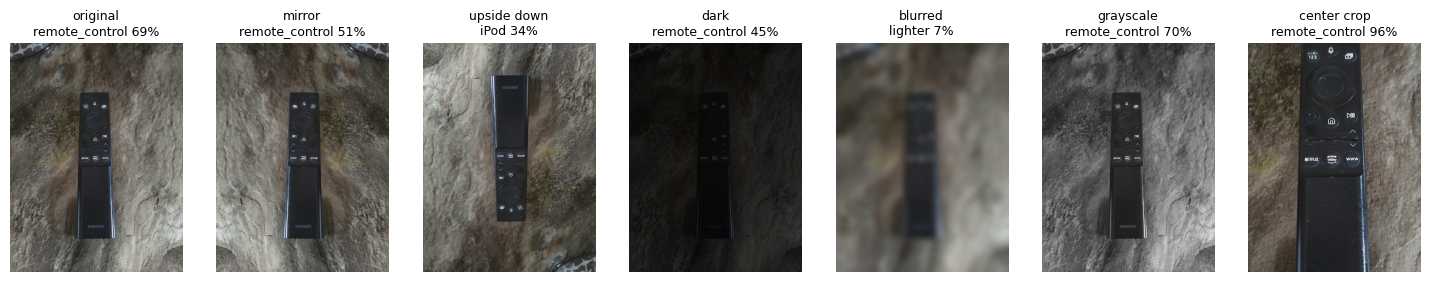

In [16]:
OBJ_PICK = 2        # change to the number of your everyday-object photo
base = open_photo(paths[OBJ_PICK])
w, h = base.size
variants = {
    "original":     base,
    "mirror":       ImageOps.mirror(base),
    "upside down":  base.rotate(180),   # TODO: turn the photo upside down (PIL: .rotate)
    "dark":         ImageEnhance.Brightness(base).enhance(0.25),
    "blurred":      base.filter(ImageFilter.GaussianBlur(radius=max(w, h) / 80)),
    "grayscale":    base.convert("L").convert("RGB"),   # TODO: grayscale but still 3 channels (PIL: .convert)
    "center crop":  base.crop((w // 4, h // 4, 3 * w // 4, 3 * h // 4)),
}
vp = model.predict(np.stack([prepare(v) for v in variants.values()]), verbose=0)
vt = tf.keras.applications.mobilenet_v2.decode_predictions(vp, top=1)

fig, axes = plt.subplots(1, len(variants), figsize=(2.6 * len(variants), 3.2))
for ax, (name, v), t in zip(axes, variants.items(), vt):
    ax.imshow(v); ax.axis("off"); ax.set_title(f"{name}\n{t[0][1]} {t[0][2]:.0%}", fontsize=9)
plt.show()

✍️ **Question 5.**
1. For each of your photos, was the top prediction right? If one was wrong, was the mistake reasonable (a similar class), or was your object simply not one of the 1,000 ImageNet classes?
2. Which changes in 4b changed the prediction or lowered the confidence the most? Give one reason the network might be sensitive to that change, thinking about what was in its training photos.
3. The network squashes every photo to 224×224. What happens to a tall or wide photo, and how could that hurt?

*Your answer:*

1. Keyboard: computer_keyboard 78% (right). Mug: cup 65%, coffee_mug 9% (right, a very similar class). Remote: remote_control 69% (right). Spoon: ladle 98% (wrong, but a reasonable mistake: ImageNet has no plain metal spoon class, only similar things like ladle and wooden_spoon). Window: sliding_door 37%, window_screen 29% (ImageNet has no plain "window" class, so it picked related classes).

2. On my remote photo, blurring changed the result the most: the confidence fell from 69% to 7% and the class became "lighter". Turning it upside down also changed the class (iPod, 34%), and darkening lowered it to 45%. Grayscale (70%) did not change anything and the center crop raised it to 96%. A blurred photo hides the buttons and fine details the network uses, and ImageNet photos are mostly sharp. Objects in ImageNet photos are also mostly upright, so an upside-down remote is unusual, and it looks like another rectangular device with buttons.

3. A tall or wide photo is squashed into 224×224, so its aspect ratio changes: a round cup becomes an oval and a long object is squeezed. The network was trained on photos with normal proportions, so distorted shapes can confuse it.

---
## 5. Inside the network

### 5a. Learned first-layer filters

The first convolution layer of MobileNetV2 (`Conv1`) has 32 filters of size 3×3×3. Nobody designed them: they were learned from ImageNet. Each is shown as a tiny color image (gray is 0). Filters that are almost all gray have weights close to 0: the network barely uses them.

Conv1 weights: (3, 3, 3, 32)  (k, k, input channels, filters)


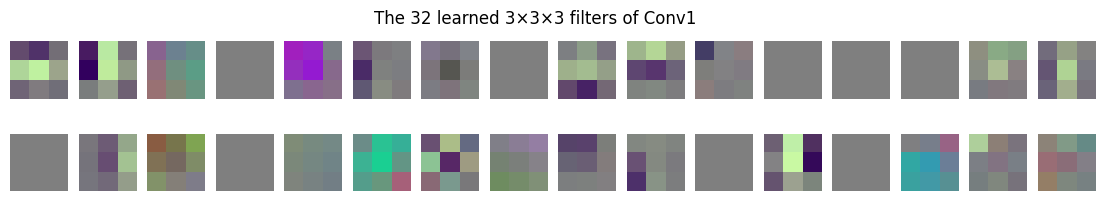

In [17]:
if 'model' not in globals():
    model = tf.keras.applications.MobileNetV2(weights="imagenet")

w1 = model.get_layer("Conv1").get_weights()[0]
print("Conv1 weights:", w1.shape, " (k, k, input channels, filters)")

v = np.abs(w1).max()
fig, axes = plt.subplots(2, 16, figsize=(14, 2.2))
for f, ax in enumerate(axes.ravel()):
    ax.imshow((w1[:, :, :, f] / v + 1) / 2, interpolation="nearest"); ax.axis("off")
plt.suptitle("The 32 learned 3×3×3 filters of Conv1")
plt.show()

### 5b. Feature maps at different depths

Build a second model that returns the outputs of four layers, from early to late, and look at the most active channels for your photo.

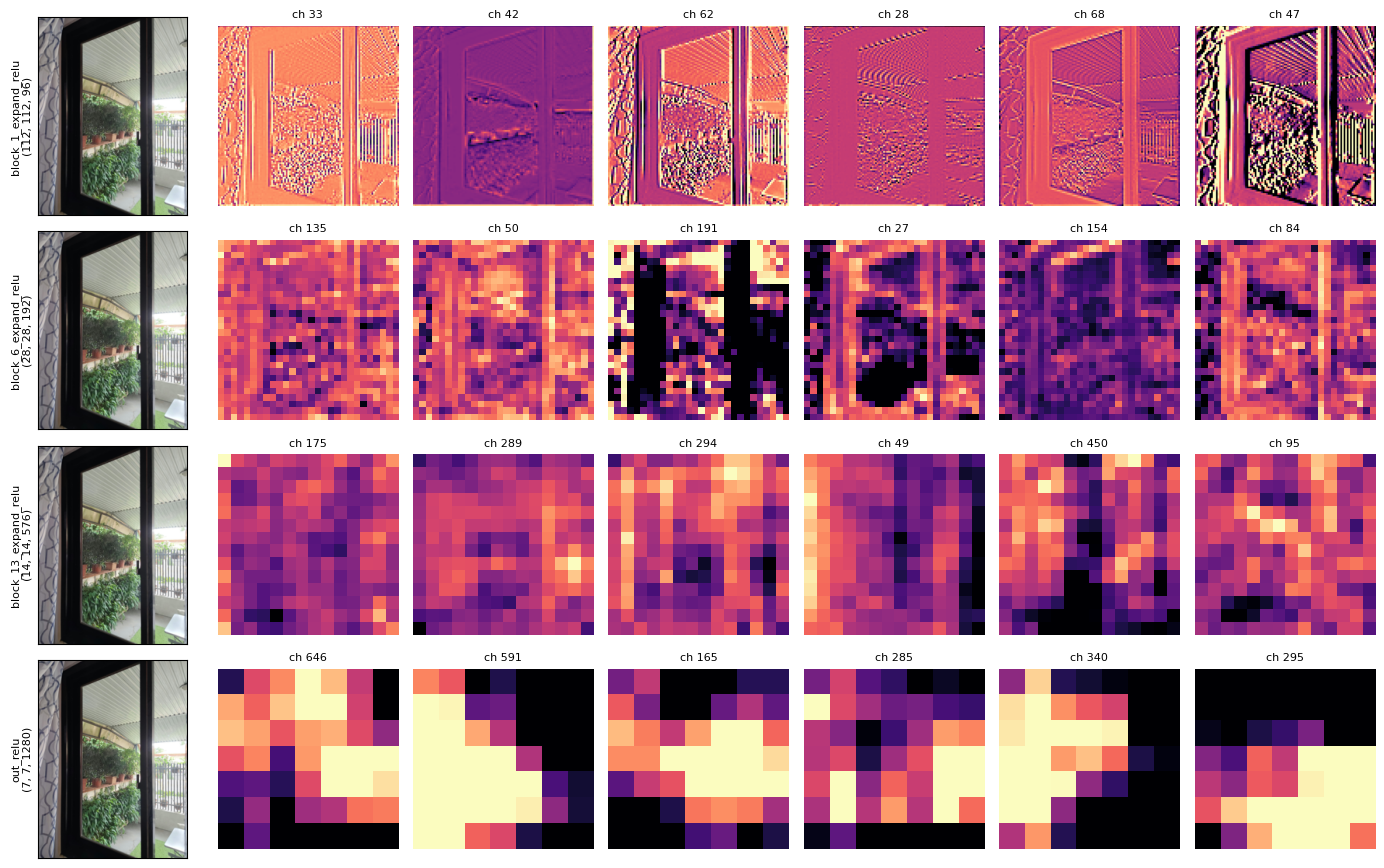

block_1_expand_relu    (112, 112, 96)   values: 1,204,224
block_6_expand_relu    (28, 28, 192)    values: 150,528
block_13_expand_relu   (14, 14, 576)    values: 112,896
out_relu               (7, 7, 1280)     values: 62,720


In [18]:
if 'prepare' not in globals():
    def prepare(pil_img):
        resized = pil_img.resize((224, 224))
        x = np.array(resized, dtype="float32")
        return tf.keras.applications.mobilenet_v2.preprocess_input(x)

layer_names = ["block_1_expand_relu", "block_6_expand_relu", "block_13_expand_relu", "out_relu"]
feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=[model.get_layer(name).output for name in layer_names]
)   # TODO: tf.keras.Model with model.input and the outputs of these layers

feats = feature_model.predict(prepare(open_photo(paths[MY_PICK]))[None], verbose=0)
fig, axes = plt.subplots(len(layer_names), 7, figsize=(14, 2.2 * len(layer_names)))
for row, (name, fmap) in zip(axes, zip(layer_names, feats)):
    fmap = fmap[0]
    row[0].imshow(images[MY_PICK]); row[0].set_ylabel(f"{name}\n{fmap.shape}", fontsize=8)
    row[0].set_xticks([]); row[0].set_yticks([])
    best = np.argsort(fmap.mean(axis=(0, 1)))[::-1][:6]      # the 6 most active channels
    for ax, ch in zip(row[1:], best):
        ax.imshow(fmap[:, :, ch], cmap="magma"); ax.set_title(f"ch {ch}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()
for name, fmap in zip(layer_names, feats):
    print(f"{name:22s} {str(fmap.shape[1:]):16s} values: {np.prod(fmap.shape[1:]):,}")

### 5c. Where does the network look? (Grad-CAM)

Grad-CAM asks: if the score of the predicted class went up, which positions of the last feature maps would be responsible? It weights each of the 1,280 maps of `out_relu` by its average gradient and adds them up. The code is given; just run it and look at your photos.

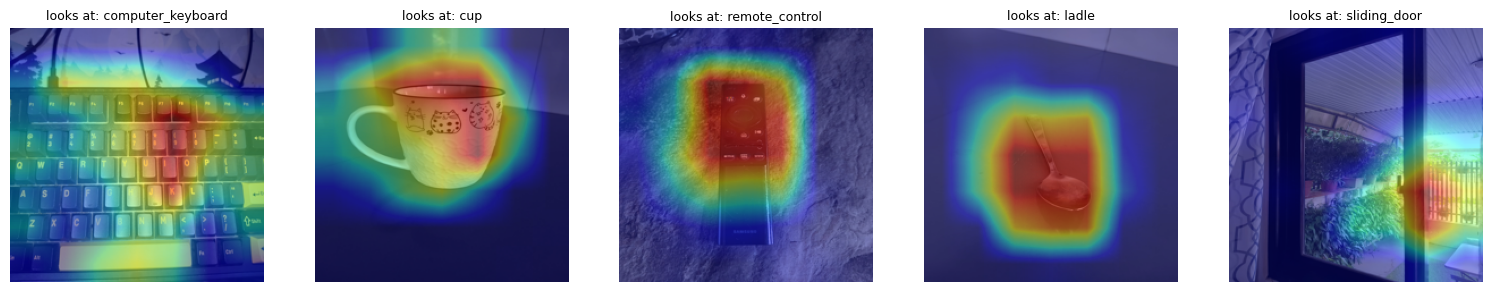

In [19]:
grad_model = tf.keras.Model(model.input, [model.get_layer("out_relu").output, model.output])

def grad_cam(x):
    with tf.GradientTape() as tape:
        fmaps, probs = grad_model(x[None])
        cls = int(tf.argmax(probs[0]))
        score = probs[:, cls]
    grads = tape.gradient(score, fmaps)[0]                 # (7, 7, 1280)
    weights = tf.reduce_mean(grads, axis=(0, 1))           # one weight per map
    cam = tf.nn.relu(tf.reduce_sum(fmaps[0] * weights, axis=-1)).numpy()
    return cam / (cam.max() + 1e-8), cls

fig, axes = plt.subplots(1, len(paths), figsize=(3.8 * len(paths), 4), squeeze=False)
for ax, p in zip(axes[0], paths):
    pil = open_photo(p)
    cam, cls = grad_cam(prepare(pil))
    name = tf.keras.applications.mobilenet_v2.decode_predictions(np.eye(1000)[cls][None], top=1)[0][0][1]
    ax.imshow(pil.resize((224, 224)))
    ax.imshow(np.array(Image.fromarray(np.uint8(cam * 255)).resize((224, 224), Image.BILINEAR)), cmap="jet", alpha=0.45)
    ax.set_title(f"looks at: {name}", fontsize=9); ax.axis("off")
plt.show()

✍️ **Question 6.**
1. Do any of the 32 learned Conv1 filters look like the hand-made kernels from Part 2 (edges in some direction, color blobs)? Describe two.
2. From `block_1` to `out_relu`, what happens to the height × width and to the number of channels? Why does a deep CNN trade spatial size for channels?
3. Compare an early feature map with a late one for your photo: which still looks like the photo, and which is more abstract?
4. In Grad-CAM, does the network look at the object itself or at the background? Give one photo where the answer matters.

*Your answer:*

1. Several filters are almost plain gray, this means that their weights are near zero. Among the others: the first filter in the top row has a light stripe in the middle row between dark rows, so it is a horizontal line/edge detector, and the second one has a light vertical stripe next to a dark one, so it is a vertical edge detector.

2. From block_1 to out_relu the height × width shrinks (112×112 to 28×28 to 14×14 to 7×7) while the number of channels grows (96 to 192 to 576 to 1280). Each downsampling step lets a unit see a larger part of the photo (a bigger receptive field).

3. The early map (block_1) still looks like my photo: the window frame, plants and fence are recognisable. The late map (out_relu) is only 7×7 blocks of bright and dark and does not look like the photo, so it is more abstract.

4. For the remote, the cup, the spoon and the keyboard the heat is on the object itself, not the background. For the window it sits on the right side of the frame near the handle, not on the plants or the view, which fits the label "sliding_door". This matters for the window photo, because the network is looking at a small door-like part and not at the whole scene.

---
## 6. Beyond CNNs: your photo as Vision Transformer patches

From the slide on the **Vision Transformer (ViT)**: the image is cut into $P \times P$ patches, each patch is flattened into one vector (a “token”), and the sequence of tokens goes into a Transformer encoder, just like the words of a sentence in Lecture 02.

tokens: (196, 768)
Check shape: True   Check patch 1 is the second patch of the top row: True


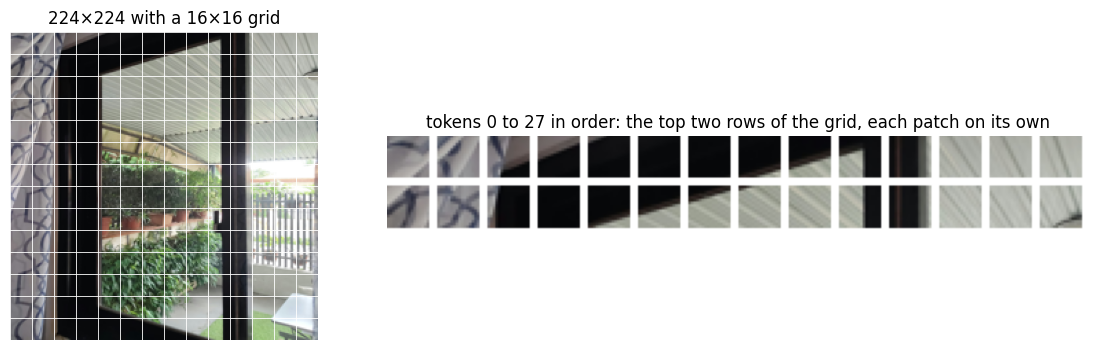

In [20]:
P = 16
x224 = np.array(open_photo(paths[MY_PICK]).resize((224, 224)))

def to_patches(x, P):
    """(H, W, C) image → (number of patches, P*P*C), patches in reading order (row by row)."""
    H, W, Cn = x.shape
    # Reshape to separate the grid blocks from local patch pixels
    grid_h = H // P
    grid_w = W // P
    reshaped = x.reshape(grid_h, P, grid_w, P, Cn)
    # Transpose to group grid cells together: (grid_h, grid_w, P, P, Cn)
    transposed = reshaped.transpose(0, 2, 1, 3, 4)
    # Flatten the grids into sequence format and flatten patch pixels
    return transposed.reshape(grid_h * grid_w, P * P * Cn)

patches = to_patches(x224, P)
print("tokens:", patches.shape)
print("Check shape:", patches.shape == (196, 768),
      "  Check patch 1 is the second patch of the top row:", np.array_equal(patches[1], x224[0:16, 16:32].reshape(-1)))

fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(1, 3, 1); ax.imshow(x224); ax.set_title("224×224 with a 16×16 grid")
for k in range(0, 225, P):
    ax.axhline(k - 0.5, color="w", lw=0.6); ax.axvline(k - 0.5, color="w", lw=0.6)
ax.axis("off")
ax = fig.add_subplot(1, 3, (2, 3))
tile = lambda p: np.pad(p.reshape(P, P, 3), ((0, 3), (0, 3), (0, 0)), constant_values=255)
strip = np.concatenate([np.concatenate([tile(p) for p in patches[r * 14:(r + 1) * 14]], axis=1) for r in range(2)], axis=0)
ax.imshow(strip); ax.set_title("tokens 0 to 27 in order: the top two rows of the grid, each patch on its own"); ax.axis("off")
plt.show()

✍️ **Question 7.**
1. How many tokens does a 224×224 image give with $P = 16$? With $P = 8$?
2. Self-attention compares every token with every token. How many pairs is that for each case?
3. Once the patches are a list of vectors, the Transformer cannot tell where each patch was in the photo. What does ViT add to fix this, and which slide of Lecture 02 is the same idea?

*Your answer:*

1. 224 / 16 = 14, so 14 × 14 = 196 tokens . With P = 8: 28 × 28 = 784 tokens.

2. 196² = 38,416 pairs for P = 16, and 784² = 614,656 pairs for P = 8.

3. ViT adds a positional embedding (position encoding) to each patch vector so the model knows where the patch came from. It is the same idea as the positional encoding for the words of a sentence in the slide 34 of Lecture 02.

---
## 7. Train a classifier on your own photos (transfer learning)

ImageNet has no class for many things around us. Teach MobileNetV2 two new classes from **your** photos, while keeping everything it already learned: freeze the pretrained network and train only a new last layer.

**Prepare your data.** Make a folder `my_dataset` with one subfolder per class, named after the class, and at least 20 photos in each:

```
my_dataset/
    mango/    IMG_001.jpg  IMG_002.jpg ...
    banana/   IMG_101.jpg  IMG_102.jpg ...
```

Zip the folder as `my_dataset.zip` and choose it when the cell below asks. (Outside Colab, put `my_dataset/` next to this notebook.)

In [21]:
DATA_DIR = "my_dataset"
if IN_COLAB and not os.path.isdir(DATA_DIR):
    up = files.upload()                                   # choose my_dataset.zip
    for name in up:
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")
    shutil.rmtree("__MACOSX", ignore_errors=True)          # junk folder that macOS adds to zips

if not os.path.isdir(DATA_DIR):
    print("No my_dataset/ folder found, so two flower classes are used for now. Your submission must use YOUR photos.")
    root = tf.keras.utils.get_file("flower_photos.tgz",
           "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz", extract=True)
    src = glob.glob(os.path.join(os.path.dirname(root), "**", "daisy"), recursive=True)[0]
    DATA_DIR = "sample_dataset"
    for cls in ["daisy", "sunflowers"]:
        os.makedirs(os.path.join(DATA_DIR, cls), exist_ok=True)
        for f in sorted(glob.glob(os.path.join(os.path.dirname(src), cls, "*.jpg")))[:40]:
            shutil.copy(f, os.path.join(DATA_DIR, cls))

for cls in sorted(os.listdir(DATA_DIR)):
    if os.path.isdir(os.path.join(DATA_DIR, cls)):
        print(f"{cls:15s} {len(os.listdir(os.path.join(DATA_DIR, cls)))} photos")

Bowl            20 photos
Plate           20 photos


Found 40 files belonging to 2 classes.
Using 30 files for training.
Found 40 files belonging to 2 classes.
Using 10 files for validation.
classes: ['Bowl', 'Plate']


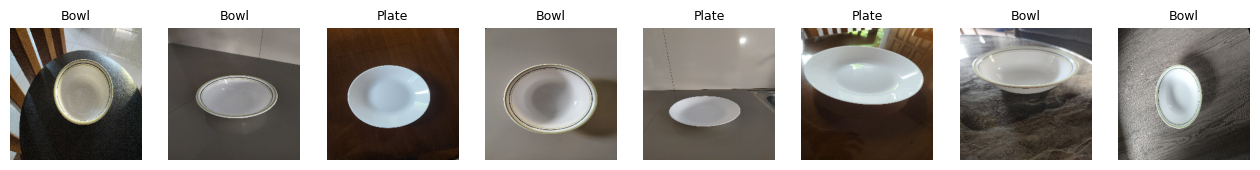

In [22]:
IMG_SIZE = (224, 224)
common = dict(validation_split=0.25, seed=173, image_size=IMG_SIZE, batch_size=16)
train_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset="training", **common)
val_ds   = tf.keras.utils.image_dataset_from_directory(DATA_DIR, subset="validation", **common)
class_names = train_ds.class_names
print("classes:", class_names)

xb, yb = next(iter(train_ds))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, x, y in zip(axes, xb, yb):
    ax.imshow(x.numpy().astype("uint8")); ax.set_title(class_names[int(y)], fontsize=9); ax.axis("off")
plt.show()

### 7b. Build and train

The new model is: random augmentation (small flips, rotations and zooms, only while training) → scale pixels to $[-1, 1]$ → **frozen** MobileNetV2 without its ImageNet head → global average pooling → a new Dense layer with one output per class.

total parameters: 2,260,546   trained here: 2,562
Epoch 1/10
2/2 - 7s - 3s/step - accuracy: 0.3333 - loss: 1.0101 - val_accuracy: 0.4000 - val_loss: 0.7748
Epoch 2/10
2/2 - 3s - 1s/step - accuracy: 0.5667 - loss: 0.7128 - val_accuracy: 0.5000 - val_loss: 0.6041
Epoch 3/10
2/2 - 6s - 3s/step - accuracy: 0.8333 - loss: 0.5103 - val_accuracy: 0.7000 - val_loss: 0.4837
Epoch 4/10
2/2 - 4s - 2s/step - accuracy: 0.8333 - loss: 0.4192 - val_accuracy: 1.0000 - val_loss: 0.4042
Epoch 5/10
2/2 - 4s - 2s/step - accuracy: 0.8667 - loss: 0.3516 - val_accuracy: 1.0000 - val_loss: 0.3302
Epoch 6/10
2/2 - 6s - 3s/step - accuracy: 0.9667 - loss: 0.2565 - val_accuracy: 1.0000 - val_loss: 0.2695
Epoch 7/10
2/2 - 7s - 4s/step - accuracy: 0.8333 - loss: 0.3968 - val_accuracy: 1.0000 - val_loss: 0.2260
Epoch 8/10
2/2 - 2s - 1s/step - accuracy: 0.9333 - loss: 0.2356 - val_accuracy: 1.0000 - val_loss: 0.1892
Epoch 9/10
2/2 - 3s - 1s/step - accuracy: 0.9667 - loss: 0.1760 - val_accuracy: 1.0000 - val_loss: 0.1

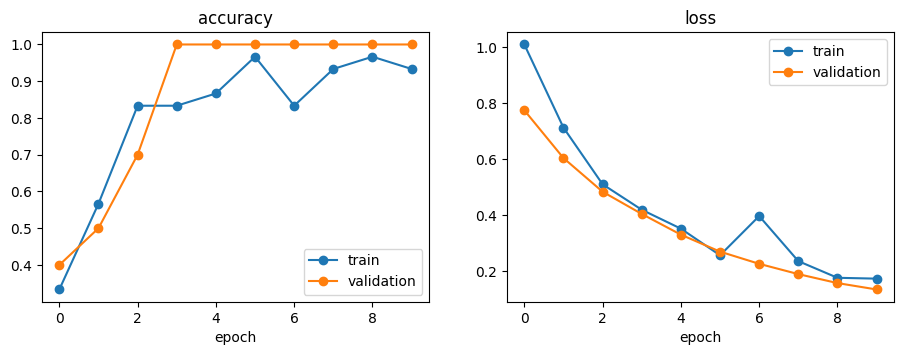

In [23]:
tf.keras.utils.set_random_seed(173)
base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False   # TODO: freeze the pretrained layers

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15),
])

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(x)           # same as preprocess_input
x = base(x, training=False)                                      # (7, 7, 1280) feature maps
x = tf.keras.layers.GlobalAveragePooling2D()(x)                  # TODO: average each of the 1280 maps into one number
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)   # TODO: one output per class, softmax
clf = tf.keras.Model(inputs, outputs)

clf.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
n_train = sum(int(tf.size(w)) for w in clf.trainable_weights)
print(f"total parameters: {clf.count_params():,}   trained here: {n_train:,}")

history = clf.fit(train_ds, validation_data=val_ds, epochs=10, verbose=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, key in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[key], "o-", label="train"); ax.plot(history.history["val_" + key], "o-", label="validation")
    ax.set_xlabel("epoch"); ax.set_title(key); ax.legend()
plt.show()

### 7c. Compare: the same data, a small CNN trained from scratch

To see what the pretrained features are worth, train a small CNN with no pretraining on exactly the same photos. The code is given.

In [24]:
tf.keras.utils.set_random_seed(173)
scratch = tf.keras.Sequential([
    tf.keras.Input(shape=IMG_SIZE + (3,)),
    augment,
    tf.keras.layers.Rescaling(1 / 255),
    tf.keras.layers.Conv2D(16, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(len(class_names), activation="softmax"),
])
scratch.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = scratch.fit(train_ds, validation_data=val_ds, epochs=10, verbose=0)
print(f"from scratch : {scratch.count_params():,} parameters, final validation accuracy {h2.history['val_accuracy'][-1]:.2f}")
print(f"transfer     : {n_train:,} trained parameters, final validation accuracy {history.history['val_accuracy'][-1]:.2f}")

from scratch : 23,714 parameters, final validation accuracy 0.30
transfer     : 2,562 trained parameters, final validation accuracy 1.00


### 7d. Mistakes, and a brand-new photo

validation accuracy: 1.0
confusion matrix (rows = true, columns = predicted):
[[3 0]
 [0 7]]


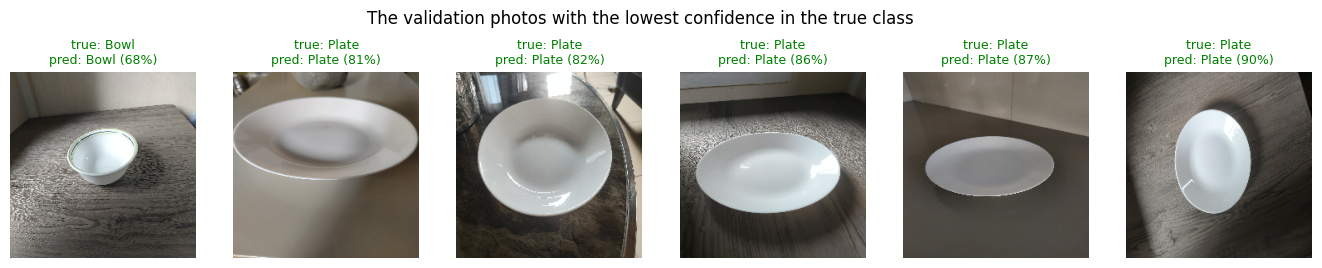

In [25]:
xs, ys = [], []
for xb, yb in val_ds:
    xs.append(xb.numpy()); ys.append(yb.numpy())
xs, ys = np.concatenate(xs), np.concatenate(ys)
probs = clf.predict(xs, verbose=0)
pred = np.argmax(probs, axis=-1)   # TODO: the predicted class index for every validation photo

print("validation accuracy:", np.mean(pred == ys).round(3))
print("confusion matrix (rows = true, columns = predicted):")
print(tf.math.confusion_matrix(ys, pred, num_classes=len(class_names)).numpy())

order = np.argsort(probs[np.arange(len(ys)), ys])[:6]          # the 6 photos the model is least sure about
fig, axes = plt.subplots(1, len(order), figsize=(2.8 * len(order), 3.2), squeeze=False)
for ax, i in zip(axes[0], order):
    ax.imshow(xs[i].astype("uint8")); ax.axis("off")
    ax.set_title(f"true: {class_names[ys[i]]}\npred: {class_names[pred[i]]} ({probs[i].max():.0%})",
                 fontsize=9, color="green" if pred[i] == ys[i] else "red")
plt.suptitle("The validation photos with the lowest confidence in the true class")
plt.show()

Now take **one new photo** of one of your two classes that is not in `my_dataset` (a new angle or a new place), and see what the model says.

Saving IMG_20261030_164115.jpg to IMG_20261030_164115.jpg


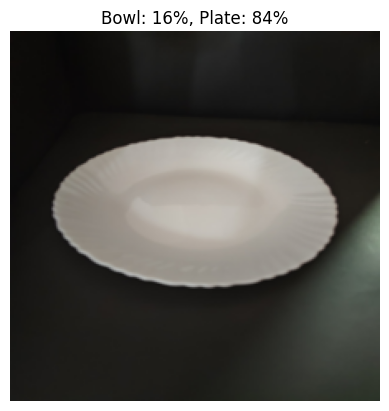

In [26]:
new_path = None
if IN_COLAB:
    up = files.upload()                           # choose one new photo
    new_path = list(up)[0] if up else None
if new_path is None:
    new_path = paths[0]                           # fallback so the cell runs; use a new photo for your submission

if 'open_photo' not in globals():
    def open_photo(path):
        return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

new_img = np.array(open_photo(new_path).resize(IMG_SIZE), dtype="float32")
p = clf.predict(new_img[None], verbose=0)[0]
plt.imshow(new_img.astype("uint8")); plt.axis("off")
plt.title(", ".join(f"{c}: {q:.0%}" for c, q in zip(class_names, p))); plt.show()

✍️ **Question 8.**
1. Report the final validation accuracy of the transfer model and of the from-scratch CNN. Why is the gap so large, given the number of photos you have?
2. Look at the least-confident validation photos. What do the mistakes (or near-mistakes) have in common: lighting, background, angle, another object in the frame?
3. Did the model get your brand-new photo right? Name one change to your dataset that would most likely make the model more reliable, and explain why.

*Your answer:*

1. The transfer model reached 1.00 validation accuracy and the from-scratch CNN only 0.30. The gap is large because the pretrained MobileNetV2 already learned general features (edges, textures, shapes) from over a million ImageNet photos, so only the last Dense layer is trained on my 30 training photos.

2. All 6 of the least-confident photos were still classified correctly (68% to 90%), so they are near-mistakes. The lowest is a bowl (68%) seen from a distance on a rough dark table with a hard shadow. The plates are mostly low-angle side views (the plate looks like a thin flat ellipse) or are on a dark glass table or dark textured wood with strong shadows.They share harsh shadows, dark textured backgrounds and angles where the depth of the bowl or the flatness of the plate is hard to see.

3. Yes, the new photo (a plate in dim light) was predicted correctly: Plate 84%, Bowl 16%, but not with very high confidence. The change I would make is to add more photos (my validation set had only 10 photos, 3 bowls and 7 plates) with more low-light and side-angle shots of different plates and bowls.

---
## 8. Wrap-up

| Lecture idea | Where you used it on your photos |
|---|---|
| Images are numbers; flattening is expensive | Part 1 |
| Convolution, kernels, stride, padding, color filters | Part 2 |
| ReLU and pooling; small shifts matter less after pooling | Part 3 |
| A deep pretrained CNN classifies (and is fooled) | Part 4 |
| Learned filters, deeper = smaller maps and more channels | Part 5 |
| ViT: images as sequences of patches | Part 6 |
| Transfer learning on a small custom dataset | Part 7 |

**Before you submit:** all photos are your own (not the sample photo or flowers), every `# TODO` is filled in, every cell has been run from top to bottom, and every ✍️ question is answered.

✍️ **Final reflection (3 to 5 sentences).** Which result on *your* photos surprised you the most? Connect it to one idea from the lecture (weight sharing, pooling, depth, receptive field, transfer learning, or attention over patches).

*Your answer:*

The result that surprised me most was the pooling test in Part 3. When I shifted my window photo by only 1 pixel, the feature map changed by 0.859 without pooling, but only 0.594 after 2×2 max pooling and 0.361 after 4×4 max pooling. I did not expect a simple max to make the network so much less sensitive to a small shift. This matches the lecture slide on pooling: it keeps the biggest value in each small block, so if an edge moves one pixel inside its block, the max stays the same. This is why a CNN can still recognize an object that moves a little in the photo, but the price is that the exact position becomes less precise.